In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split

In [4]:
df= pd.read_csv("raw_listings.csv")
print("Data loaded successfully")

Data loaded successfully


In [5]:
print("Data info:")
print(df.info())
print("Data shape:")
print(df.shape)
print("Statistical summary:")
print(df.describe())
print("Missing vallues:")
print(df.isnull().sum())
print("Duplicate rows:")
print(df.duplicated().sum())

Data info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   source         420 non-null    object 
 1   location       420 non-null    object 
 2   address        420 non-null    object 
 3   property_type  420 non-null    object 
 4   bedrooms       411 non-null    float64
 5   bathrooms      377 non-null    float64
 6   parking        419 non-null    float64
 7   size_sqft      420 non-null    int64  
 8   price_kes      420 non-null    int64  
 9   listing_url    420 non-null    object 
 10  listing_date   420 non-null    object 
dtypes: float64(3), int64(2), object(6)
memory usage: 36.2+ KB
None
Data shape:
(420, 11)
Statistical summary:
         bedrooms   bathrooms     parking     size_sqft     price_kes
count  411.000000  377.000000  419.000000    420.000000  4.200000e+02
mean     2.274939    2.437666    2.136038   1560.952381  1.83

In [6]:
#inspecting and handling the duplicates
# Identify duplicate rows, excluding the URL column
duplicate_mask = df.duplicated(
    subset=df.columns.drop('listing_url'),
    keep=False
)

# Display all matching rows
duplicates = df[duplicate_mask]

print("Total rows involved in duplicates:", len(duplicates))

Total rows involved in duplicates: 311


In [7]:
# Remove duplicates based on all columns except URL
df = df.drop_duplicates(
    subset=df.columns.drop('listing_url'),
    keep='first'
)

In [8]:
df = df.drop(columns=['listing_url'])

In [9]:
print("Dataset shape:", df.shape)

print("Remaining duplicates:", df.duplicated().sum())

Dataset shape: (207, 10)
Remaining duplicates: 0


In [10]:
#summary after handling duplicates
print("Data info:")
print(df.info())
print("Data shape:")
print(df.shape)
print("Statistical summary:")
print(df.describe())
print("Missing vallues:")
print(df.isnull().sum())
print("Duplicate rows:")
print(df.duplicated().sum())

Data info:
<class 'pandas.core.frame.DataFrame'>
Index: 207 entries, 0 to 416
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   source         207 non-null    object 
 1   location       207 non-null    object 
 2   address        207 non-null    object 
 3   property_type  207 non-null    object 
 4   bedrooms       203 non-null    float64
 5   bathrooms      175 non-null    float64
 6   parking        206 non-null    float64
 7   size_sqft      207 non-null    int64  
 8   price_kes      207 non-null    int64  
 9   listing_date   207 non-null    object 
dtypes: float64(3), int64(2), object(5)
memory usage: 17.8+ KB
None
Data shape:
(207, 10)
Statistical summary:
         bedrooms   bathrooms     parking     size_sqft     price_kes
count  203.000000  175.000000  206.000000    207.000000  2.070000e+02
mean     2.512315    2.542857    2.126214   1822.859903  2.238362e+07
std      1.256112    1.468889    1.68018

In [11]:
#changing the listing_date column to datetime format
df['listing_date'] = pd.to_datetime(df['listing_date'], errors='coerce')
print(df['listing_date'].dtype)

datetime64[ns]


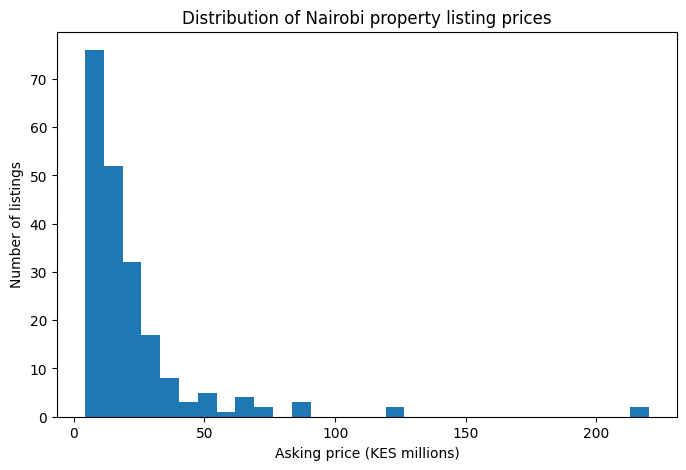

In [12]:
#target distribution
plt.figure(figsize=(8, 5))
plt.hist(df["price_kes"] / 1_000_000, bins=30)
plt.xlabel("Asking price (KES millions)")
plt.ylabel("Number of listings")
plt.title("Distribution of Nairobi property listing prices")
plt.show()

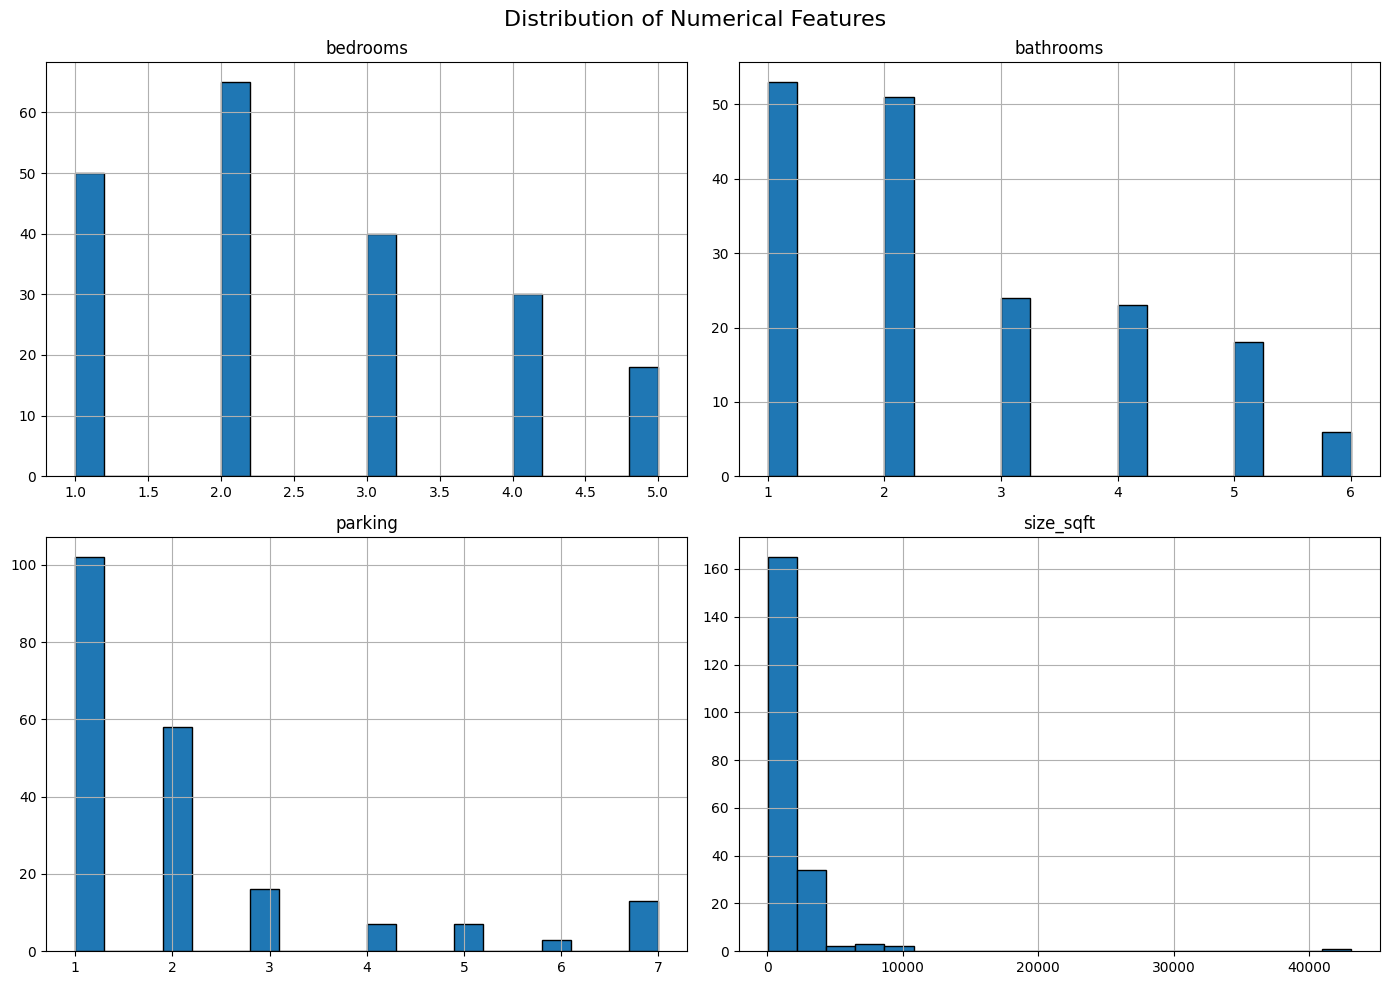

In [13]:
#distribution of numerical features
# Select numerical features, excluding the target variable
numerical_features = df.select_dtypes(include='number').drop(columns=['price_kes'])

# Plot distributions
numerical_features.hist(
    figsize=(14, 10),
    bins=20,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

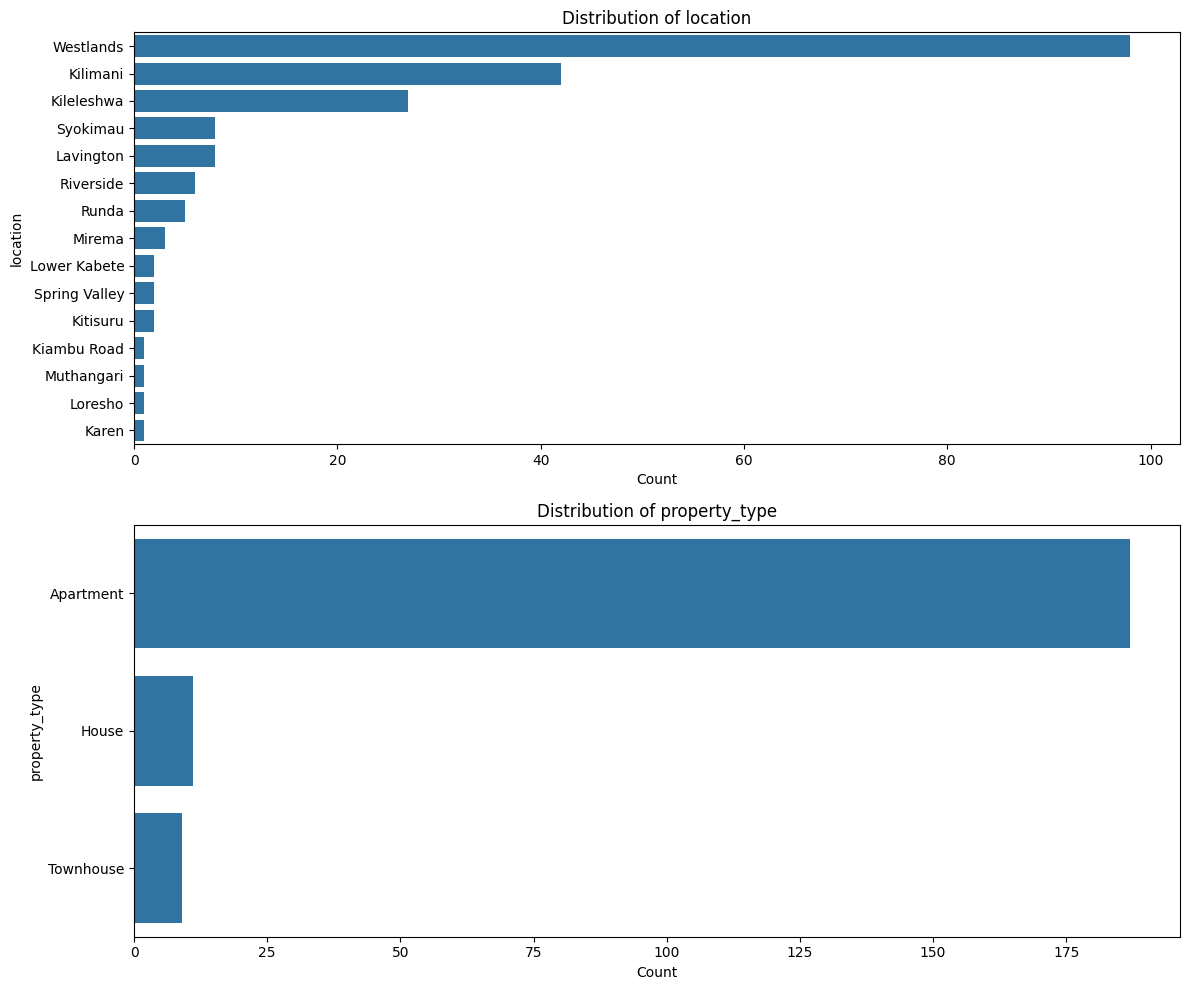

In [14]:
#distribution of categorical features
# Select categorical features
categorical_features = df.select_dtypes(include=['object', 'category'])

categorical_features = categorical_features.drop(
    columns=['source','address',],
    errors='ignore'
)
n = len(categorical_features.columns)

# Create subplots
fig, axes = plt.subplots(n, 1, figsize=(12, 5*n))

if n == 1:
    axes = [axes]

# Plot each categorical feature
for ax, col in zip(axes, categorical_features.columns):

    sns.countplot(
        data=df,
        y=col,
        order=df[col].value_counts().index,
        ax=ax
    )

    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel('Count')
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

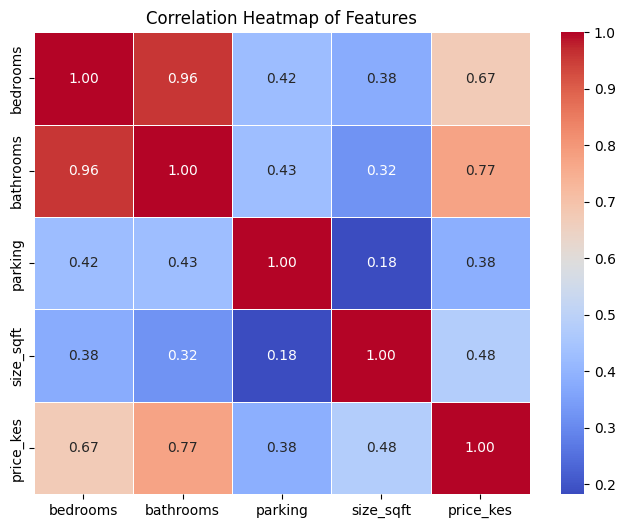

In [15]:
#relationships
# Calculate correlation matrix
correlation = df.select_dtypes(include=np.number).corr()
# Plot correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation Heatmap of Features')
plt.show()

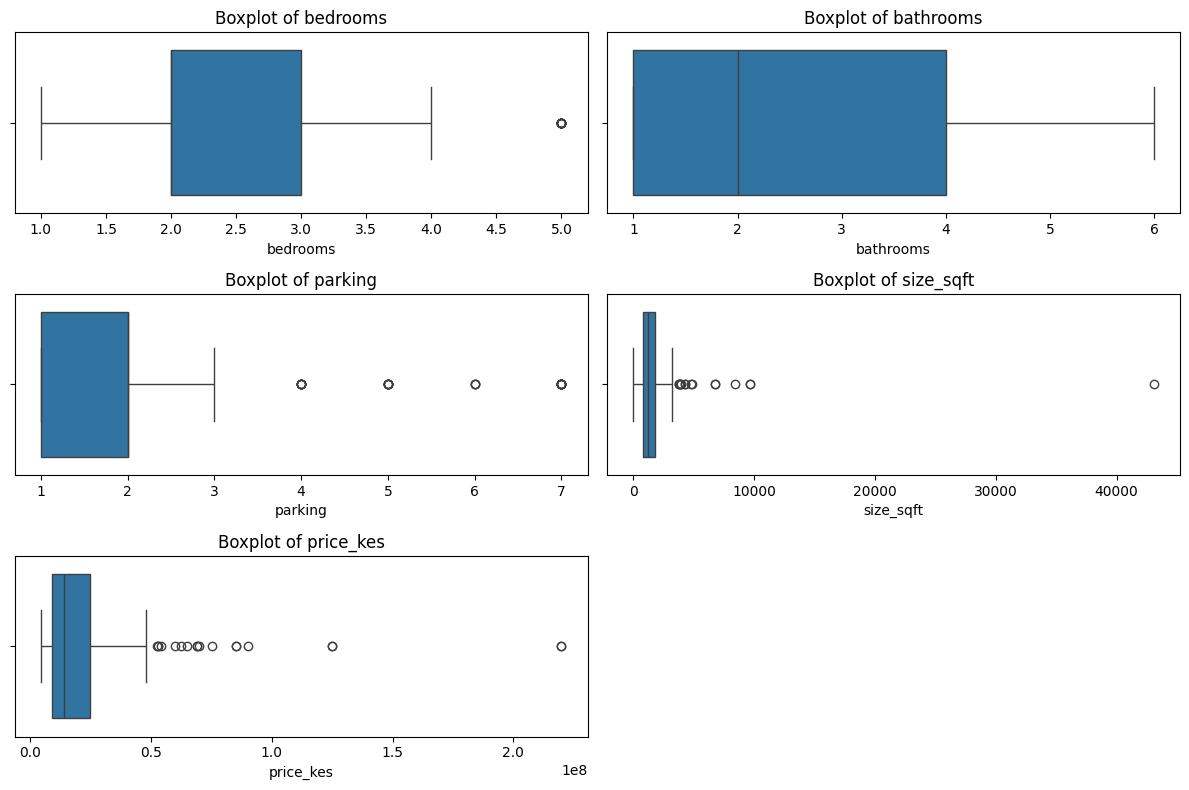

In [16]:
#investigating outliers
# Select numerical columns
numerical_cols = df.select_dtypes(include=np.number).columns
# Boxplots for numerical columns
plt.figure(figsize=(12, 8))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(3, 2, i)
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

In [17]:
# Calculate outlier boundaries using IQR
for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Number of potential outliers:", len(outliers))


Column: bedrooms
Lower bound: 0.5
Upper bound: 4.5
Number of potential outliers: 18

Column: bathrooms
Lower bound: -3.5
Upper bound: 8.5
Number of potential outliers: 0

Column: parking
Lower bound: -0.5
Upper bound: 3.5
Number of potential outliers: 30

Column: size_sqft
Lower bound: -751.75
Upper bound: 3378.25
Number of potential outliers: 16

Column: price_kes
Lower bound: -14725000.0
Upper bound: 48195000.0
Number of potential outliers: 18


In [18]:
# Inspect unusually expensive properties
df.nlargest(10, 'price_kes')[
    ['location', 'property_type', 'bedrooms',
     'bathrooms', 'size_sqft', 'price_kes']
]

,location,property_type,bedrooms,bathrooms,size_sqft,price_kes
325,Lavington,Townhouse,5.0,NaN,9688,220000000
326,Lavington,House,5.0,NaN,9688,220000000
351,Lavington,Townhouse,5.0,NaN,6781,125000000
395,Lavington,House,5.0,NaN,6781,125000000
397,Karen,Townhouse,4.0,4.0,3229,90000000
257,Westlands,Townhouse,4.0,5.0,1044,85000000
389,Kitisuru,House,5.0,4.0,54,85000000
379,Loresho,Apartment,4.0,5.0,43099,75000000
318,Lavington,Townhouse,5.0,NaN,4844,70000000
313,Lavington,House,5.0,NaN,4306,69000000


In [19]:
# Inspect the 10 largest properties
df.nlargest(10, 'size_sqft')[
    ['location', 'property_type', 'bedrooms',
     'bathrooms', 'size_sqft', 'price_kes']
]

,location,property_type,bedrooms,bathrooms,size_sqft,price_kes
379,Loresho,Apartment,4.0,5.0,43099,75000000
325,Lavington,Townhouse,5.0,NaN,9688,220000000
326,Lavington,House,5.0,NaN,9688,220000000
214,Lavington,Apartment,3.0,4.0,8407,30000000
351,Lavington,Townhouse,5.0,NaN,6781,125000000
395,Lavington,House,5.0,NaN,6781,125000000
318,Lavington,Townhouse,5.0,NaN,4844,70000000
139,Kilimani,Apartment,5.0,NaN,4790,62500000
313,Lavington,House,5.0,NaN,4306,69000000
314,Lavington,Townhouse,5.0,NaN,4306,69000000


In [20]:
# Correct the Loresho apartment's square footage
df.loc[
    df['size_sqft'] == 43099,
    'size_sqft'
] = 4309

In [21]:
#correct the kitusuru house
df['size_error'] = df['size_sqft'].isin([54])
df.loc[
    df['size_error'], 'size_sqft'
] = np.nan

In [22]:
df.isnull().sum()

,0
source,0
location,0
address,0
property_type,0
bedrooms,4
bathrooms,32
parking,1
size_sqft,1
price_kes,0
listing_date,0


In [23]:
key = ['location', 'bedrooms', 'size_sqft', 'price_kes']
near_dup = df.duplicated(subset=key, keep=False)
print("Rows involved in near-duplicates:", near_dup.sum())
display(df[near_dup].sort_values(key)[['location','property_type','bedrooms','bathrooms','size_sqft','price_kes']].head(20))

df = df.drop_duplicates(subset=key, keep='first')
print("Dataset shape after near-duplicate removal:", df.shape)

display(df[df['size_sqft'] < 300][['location','property_type','bedrooms','size_sqft','price_kes']])

Rows involved in near-duplicates: 58


,location,property_type,bedrooms,bathrooms,size_sqft,price_kes
55,Kileleshwa,Apartment,1.0,1.0,700.0,5110000
210,Kileleshwa,Apartment,1.0,1.0,700.0,5110000
52,Kileleshwa,Apartment,2.0,2.0,807.0,7150000
53,Kileleshwa,Apartment,2.0,2.0,807.0,7150000
157,Kileleshwa,Apartment,2.0,2.0,807.0,7150000
49,Kileleshwa,Apartment,2.0,2.0,1087.0,9210000
50,Kileleshwa,Apartment,2.0,2.0,1087.0,9210000
118,Kileleshwa,Apartment,4.0,5.0,2454.0,26000000
321,Kileleshwa,Apartment,4.0,4.0,2454.0,26000000
162,Kilimani,Apartment,1.0,1.0,807.0,8200000


Dataset shape after near-duplicate removal: (173, 11)


,location,property_type,bedrooms,size_sqft,price_kes
219,Kilimani,Apartment,4.0,129.0,25000000
258,Westlands,Apartment,2.0,97.0,14000000
287,Spring Valley,Apartment,3.0,43.0,23100000
378,Kitisuru,Townhouse,4.0,32.0,60000000


In [24]:
# Separate independent variables and target variable
X = df[['location','property_type','bedrooms','bathrooms','parking','size_sqft']]
y = df['price_kes']

# Display features and target
print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

Features:


,location,property_type,bedrooms,bathrooms,parking,size_sqft
0,Westlands,Apartment,1.0,1.0,1.0,732.0
2,Syokimau,Apartment,2.0,2.0,1.0,990.0
3,Westlands,Apartment,1.0,1.0,1.0,753.0
4,Westlands,Apartment,1.0,1.0,1.0,721.0
5,Westlands,Apartment,1.0,1.0,1.0,1173.0



Target:


,price_kes
0,8940000
2,7500000
3,9200000
4,9000000
5,13800000


In [25]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values in features:")
print(X.isnull().sum())

Features shape: (173, 6)
Target shape: (173,)

Missing values in features:
location          0
property_type     0
bedrooms          4
bathrooms        25
parking           1
size_sqft         1
dtype: int64


In [26]:
# Split into training (70%) and temporary (30%) sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=1089
)

In [27]:
# Split temporary data into validation (15%) and test (15%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=1089
)

In [28]:
print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

Training set: (121, 6) (121,)
Validation set: (26, 6) (26,)
Test set: (26, 6) (26,)


In [29]:
# Numerical features
numerical_features = [
    'bedrooms',
    'bathrooms',
    'parking',
    'size_sqft'
]

# Categorical features
categorical_features = [
    'location',
    'property_type'
]

In [30]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [31]:
#imputing missing values and scaling numerical features
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [32]:
#imputing missing values and encoding categorical features
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [33]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [34]:
# Learn preprocessing parameters from training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the learned transformations to validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

In [35]:
print("Training data:", X_train_processed.shape)
print("Validation data:", X_val_processed.shape)
print("Test data:", X_test_processed.shape)

Training data: (121, 21)
Validation data: (26, 21)
Test data: (26, 21)


In [36]:
print(y_train.describe())
print("\nTraining target median:", y_train.median())
print("Training target mean:", y_train.mean())

count    1.210000e+02
mean     2.217521e+07
std      2.672718e+07
min      4.310000e+06
25%      9.000000e+06
50%      1.360000e+07
75%      2.450000e+07
max      2.200000e+08
Name: price_kes, dtype: float64

Training target median: 13600000.0
Training target mean: 22175206.611570247


In [37]:
#baseline model
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create the two baseline models
dummy_mean = DummyRegressor(strategy='mean')
dummy_median = DummyRegressor(strategy='median')

# Train using training data only
dummy_mean.fit(X_train_processed, y_train)
dummy_median.fit(X_train_processed, y_train)

# Make validation predictions
y_pred_mean = dummy_mean.predict(X_val_processed)
y_pred_median = dummy_median.predict(X_val_processed)

# Evaluation function
def evaluate_baseline(y_true, y_pred, model_name):
    return {
        'Model': model_name,
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': mean_squared_error(y_true, y_pred) ** 0.5,
        'R2': r2_score(y_true, y_pred)
    }

# Compare the models
results = pd.DataFrame([
    evaluate_baseline(y_val, y_pred_mean, 'Mean Baseline'),
    evaluate_baseline(y_val, y_pred_median, 'Median Baseline')
])

print(results)

             Model           MAE          RMSE        R2
0    Mean Baseline  1.190856e+07  1.512080e+07 -0.080447
1  Median Baseline  9.066154e+06  1.521218e+07 -0.093546


In [38]:
# Generate predictions on the test set
y_test_pred_mean = dummy_mean.predict(X_test_processed)
y_test_pred_median = dummy_median.predict(X_test_processed)

# Evaluate both baselines
test_results = pd.DataFrame([
    evaluate_baseline(y_test, y_test_pred_mean, 'Mean Baseline'),
    evaluate_baseline(y_test, y_test_pred_median, 'Median Baseline')
])

print(test_results)

             Model           MAE          RMSE        R2
0    Mean Baseline  1.183953e+07  1.556070e+07 -0.084790
1  Median Baseline  8.912500e+06  1.552605e+07 -0.079965


In [39]:
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score, cross_val_predict

lr_preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('scaler', StandardScaler())]), numerical_features),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('encoder', OneHotEncoder(drop='first',
                                                handle_unknown='infrequent_if_exist',
                                                min_frequency=5))]), categorical_features),
])

def lr_make_model(estimator, log_target=True):
    pipe = Pipeline([('prep', clone(lr_preprocessor)), ('model', estimator)])
    if log_target:
        return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)
    return pipe

def lr_evaluate(y_true, y_pred, name):
    y_true = np.asarray(y_true)
    return {
        'Model': name,
        'MAE (KES)': mean_absolute_error(y_true, y_pred),
        'RMSE (KES)': mean_squared_error(y_true, y_pred) ** 0.5,
        'R2': r2_score(y_true, y_pred),
        'MedAPE (%)': np.median(np.abs(y_pred - y_true) / y_true) * 100,
    }

In [40]:
lr_candidates = {
    'OLS (raw price)':          lr_make_model(LinearRegression(), log_target=False),
    'OLS (log price)':          lr_make_model(LinearRegression()),
    'Ridge (log, alpha=1)':     lr_make_model(Ridge(alpha=1.0)),
    'Lasso (log, alpha=0.01)':  lr_make_model(Lasso(alpha=0.01, max_iter=50000)),
    'ElasticNet (log, a=0.01)': lr_make_model(ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=50000)),
}

lr_rows = [
    lr_evaluate(y_val, dummy_mean.predict(X_val_processed), 'Mean baseline'),
    lr_evaluate(y_val, dummy_median.predict(X_val_processed), 'Median baseline'),
]
for lr_name, lr_model in lr_candidates.items():
    lr_model.fit(X_train, y_train)
    lr_rows.append(lr_evaluate(y_val, lr_model.predict(X_val), lr_name))

lr_val_results = pd.DataFrame(lr_rows).set_index('Model')
display(lr_val_results.round(2))

,MAE (KES),RMSE (KES),R2,MedAPE (%)
Model,,,,
Mean baseline,11908556.90,15120795.38,-0.08,73.24
Median baseline,9066153.85,15212180.34,-0.09,49.61
OLS (raw price),3468466.23,7732618.10,0.72,12.73
OLS (log price),3814946.97,8721028.39,0.64,10.59
"Ridge (log, alpha=1)",3619030.06,7987848.82,0.70,11.36
"Lasso (log, alpha=0.01)",3649696.17,8021228.82,0.70,10.00
"ElasticNet (log, a=0.01)",3670796.62,8094973.00,0.69,10.33


In [41]:
X_dev = pd.concat([X_train, X_val])
y_dev = pd.concat([y_train, y_val])
cv = KFold(n_splits=5, shuffle=True, random_state=1089)

lr_searches = {
    'Ridge': (lr_make_model(Ridge()), {'regressor__model__alpha': np.logspace(-3, 3, 25)}),
    'Lasso': (lr_make_model(Lasso(max_iter=50000)), {'regressor__model__alpha': np.logspace(-4, 0, 25)}),
    'ElasticNet': (lr_make_model(ElasticNet(max_iter=50000)),
                   {'regressor__model__alpha': np.logspace(-4, 0, 13),
                    'regressor__model__l1_ratio': [0.2, 0.5, 0.8]}),
}

lr_cv_mae, lr_fitted = {}, {}
for lr_name, (lr_est, lr_grid) in lr_searches.items():
    lr_gs = GridSearchCV(lr_est, lr_grid, cv=cv, scoring='neg_mean_absolute_error')
    lr_gs.fit(X_dev, y_dev)
    lr_cv_mae[lr_name] = -lr_gs.best_score_
    lr_fitted[lr_name] = lr_gs.best_estimator_
    print(f"{lr_name}: best params = {lr_gs.best_params_}, CV MAE = {-lr_gs.best_score_:,.0f}")

lr_ols_log = lr_make_model(LinearRegression())
lr_cv_mae['OLS (log price)'] = -cross_val_score(lr_ols_log, X_dev, y_dev, cv=cv,
                                                scoring='neg_mean_absolute_error').mean()
lr_fitted['OLS (log price)'] = lr_ols_log.fit(X_dev, y_dev)
lr_cv_mae['OLS (raw price)'] = -cross_val_score(lr_make_model(LinearRegression(), log_target=False),
                                                X_dev, y_dev, cv=cv, scoring='neg_mean_absolute_error').mean()

display(pd.Series(lr_cv_mae, name='CV MAE (KES)').sort_values().round(0).to_frame())

lr_best_name = min((k for k in lr_cv_mae if k != 'OLS (raw price)'), key=lr_cv_mae.get)
lr_best_model = lr_fitted[lr_best_name]
print("Selected model:", lr_best_name)

# ---- final test evaluation (used once) ----
lr_test_pred = lr_best_model.predict(X_test)
lr_final = pd.DataFrame([
    lr_evaluate(y_test, dummy_mean.predict(X_test_processed), 'Mean baseline'),
    lr_evaluate(y_test, dummy_median.predict(X_test_processed), 'Median baseline'),
    lr_evaluate(y_test, lr_test_pred, f'{lr_best_name} (tuned)'),
]).set_index('Model')
display(lr_final.round(2))

lr_rng = np.random.default_rng(1089)
lr_abs_err = np.abs(y_test.values - lr_test_pred)
lr_boot = [lr_rng.choice(lr_abs_err, size=len(lr_abs_err), replace=True).mean() for _ in range(2000)]
print(f"Test MAE = {lr_abs_err.mean():,.0f} KES, 95% bootstrap interval "
      f"[{np.percentile(lr_boot, 2.5):,.0f}, {np.percentile(lr_boot, 97.5):,.0f}]")

Ridge: best params = {'regressor__model__alpha': np.float64(0.001)}, CV MAE = 4,959,905
Lasso: best params = {'regressor__model__alpha': np.float64(0.0001)}, CV MAE = 4,960,741
ElasticNet: best params = {'regressor__model__alpha': np.float64(0.0001), 'regressor__model__l1_ratio': 0.8}, CV MAE = 4,960,949


,CV MAE (KES)
OLS (log price),4959724.0
Ridge,4959905.0
Lasso,4960741.0
ElasticNet,4960949.0
OLS (raw price),5663525.0


Selected model: OLS (log price)


,MAE (KES),RMSE (KES),R2,MedAPE (%)
Model,,,,
Mean baseline,11839534.33,15560695.76,-0.08,69.22
Median baseline,8912500.00,15526051.71,-0.08,44.73
OLS (log price) (tuned),2681370.56,3954285.35,0.93,11.14


Test MAE = 2,681,371 KES, 95% bootstrap interval [1,651,117, 3,922,656]


,feature,coef,price_effect_%
9,cat__property_type_Townhouse,0.809,124.594
0,num__bedrooms,0.423,52.724
5,cat__location_Riverside,0.393,48.079
10,cat__property_type_infrequent_sklearn,0.343,40.980
6,cat__location_Syokimau,-0.343,-29.042
7,cat__location_Westlands,0.232,26.113
3,num__size_sqft,0.167,18.220
4,cat__location_Kilimani,0.154,16.685
1,num__bathrooms,0.103,10.816
8,cat__location_infrequent_sklearn,0.066,6.844


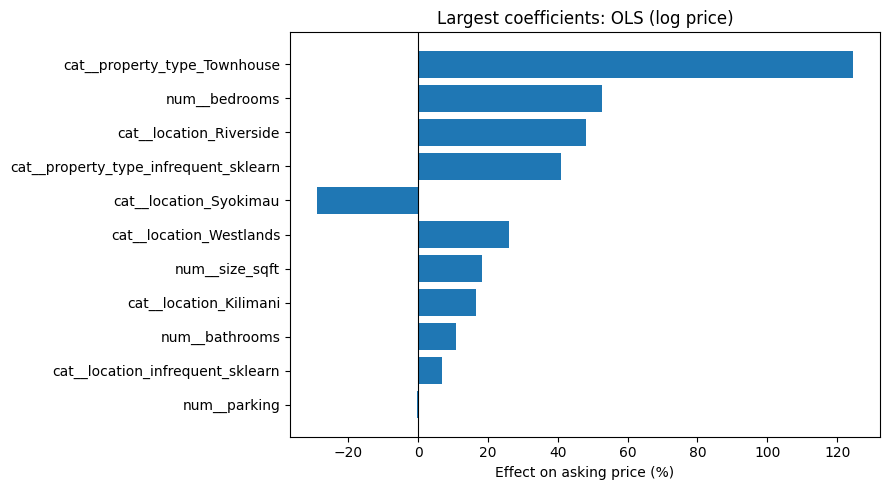

In [42]:
lr_prep = lr_best_model.regressor_.named_steps['prep']
lr_lin = lr_best_model.regressor_.named_steps['model']

lr_coef = pd.DataFrame({'feature': lr_prep.get_feature_names_out(), 'coef': lr_lin.coef_})
lr_coef['price_effect_%'] = (np.exp(lr_coef['coef']) - 1) * 100
lr_coef = lr_coef.reindex(lr_coef['coef'].abs().sort_values(ascending=False).index)
display(lr_coef.round(3))

lr_top = lr_coef.head(12).iloc[::-1]
plt.figure(figsize=(9, 5))
plt.barh(lr_top['feature'], lr_top['price_effect_%'])
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Effect on asking price (%)')
plt.title(f'Largest coefficients: {lr_best_name}')
plt.tight_layout()
plt.show()

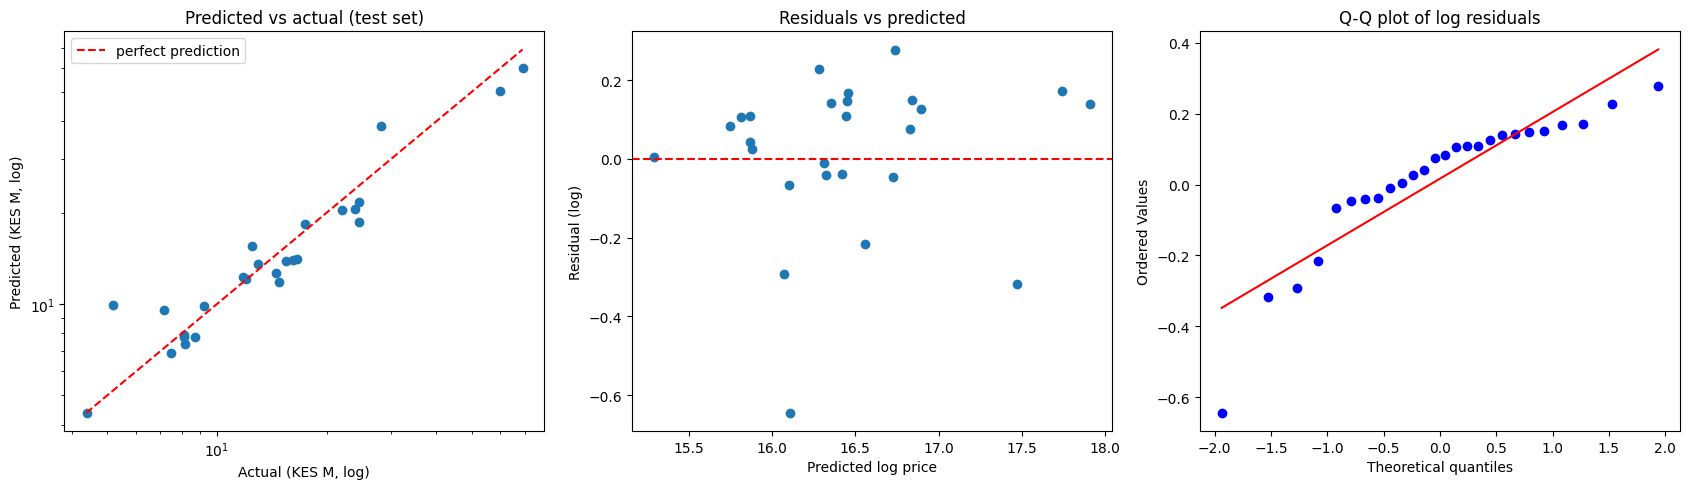

,location,property_type,bedrooms,size_sqft,actual,predicted,abs_pct_error
34,Kilimani,Apartment,NaN,463.0,5200000,9911601.6,90.6
86,Kilimani,Apartment,5.0,2799.0,28200000,38740815.7,37.4
156,Kileleshwa,Apartment,2.0,861.0,7150000,9569762.1,33.8
9,Westlands,Apartment,3.0,1668.0,24600000,18640254.4,24.2
45,Kileleshwa,Apartment,3.0,1464.0,12500000,15500670.2,24.0


,count,median
property_type,,
Apartment,137,14.2
House,4,41.3
Townhouse,6,25.2


,count,median
price_band,,
low,49,19.9
mid,49,11.7
high,49,21.3


,count,median
location,,
Syokimau,6,28.4
Kilimani,34,19.3
Kileleshwa,19,18.0
Westlands,66,11.5
Riverside,6,9.1


direction,over,under
price_band,,
low,0.63,0.37
mid,0.43,0.57
high,0.41,0.59


In [43]:
from scipy import stats

lr_res = X_test.copy()
lr_res['actual'] = y_test.values
lr_res['predicted'] = lr_test_pred
lr_res['abs_pct_error'] = np.abs(lr_res['predicted'] - lr_res['actual']) / lr_res['actual'] * 100

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ax[0].scatter(lr_res['actual']/1e6, lr_res['predicted']/1e6)
lim = [lr_res[['actual','predicted']].min().min()/1e6, lr_res[['actual','predicted']].max().max()/1e6]
ax[0].plot(lim, lim, 'r--', label='perfect prediction')
ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('Actual (KES M, log)'); ax[0].set_ylabel('Predicted (KES M, log)')
ax[0].set_title('Predicted vs actual (test set)'); ax[0].legend()

lr_log_resid = np.log(lr_res['actual']) - np.log(lr_res['predicted'])
ax[1].scatter(np.log(lr_res['predicted']), lr_log_resid)
ax[1].axhline(0, color='red', linestyle='--')
ax[1].set_xlabel('Predicted log price'); ax[1].set_ylabel('Residual (log)')
ax[1].set_title('Residuals vs predicted')
stats.probplot(lr_log_resid, dist='norm', plot=ax[2]); ax[2].set_title('Q-Q plot of log residuals')
plt.tight_layout(); plt.show()

display(lr_res.sort_values('abs_pct_error', ascending=False).head(5)
        [['location','property_type','bedrooms','size_sqft','actual','predicted','abs_pct_error']].round(1))

# Out-of-fold errors on all development rows (more stable than the small test set)
lr_oof = cross_val_predict(clone(lr_best_model), X_dev, y_dev, cv=cv)
lr_oof_df = X_dev.copy()
lr_oof_df['actual'] = y_dev.values
lr_oof_df['predicted'] = lr_oof
lr_oof_df['abs_pct_error'] = np.abs(lr_oof - lr_oof_df['actual']) / lr_oof_df['actual'] * 100
lr_oof_df['price_band'] = pd.qcut(lr_oof_df['actual'], 3, labels=['low','mid','high'])
lr_oof_df['direction'] = np.where(lr_oof_df['predicted'] > lr_oof_df['actual'], 'over', 'under')

for col in ['property_type', 'price_band']:
    display(lr_oof_df.groupby(col, observed=True)['abs_pct_error'].agg(['count','median']).round(1))
lr_loc = lr_oof_df.groupby('location')['abs_pct_error'].agg(['count','median']).round(1)
display(lr_loc[lr_loc['count'] >= 5].sort_values('median', ascending=False))
display(pd.crosstab(lr_oof_df['price_band'], lr_oof_df['direction'], normalize='index').round(2))

## Decision Tree Regression

A decision tree predicts price by splitting the data on questions such as *"bedrooms <= 2.5?"* and averaging the prices in each final leaf. It needs no feature scaling and can capture non-linear effects, but an unrestricted tree memorises the training data, so we (1) compare shallow and deep trees on the validation set, (2) tune depth and leaf-size with 5-fold cross-validation on train+validation only, and (3) report the held-out test set once.

Run this section after the linear-model cells (it reuses `X_train`, `X_val`, `X_test`, `X_dev`, `y_*`, `cv`, `dummy_mean`/`dummy_median` and, for comparison, `lr_best_model`).

In [44]:
# ================= DECISION TREE REGRESSION =================
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text

# Trees split on thresholds, so scaling is unnecessary. We only impute and encode.
dt_preprocessor = ColumnTransformer(transformers=[
    ('num', SimpleImputer(strategy='median'), numerical_features),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('encoder', OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                min_frequency=5))]), categorical_features),
])

def dt_make_model(max_depth=None, min_samples_leaf=1, min_samples_split=2,
                  ccp_alpha=0.0, log_target=True):
    tree = DecisionTreeRegressor(max_depth=max_depth,
                                 min_samples_leaf=min_samples_leaf,
                                 min_samples_split=min_samples_split,
                                 ccp_alpha=ccp_alpha,
                                 random_state=1089)
    pipe = Pipeline([('prep', clone(dt_preprocessor)), ('model', tree)])
    if log_target:
        return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)
    return pipe

def dt_evaluate(y_true, y_pred, name):
    y_true = np.asarray(y_true)
    return {
        'Model': name,
        'MAE (KES)': mean_absolute_error(y_true, y_pred),
        'RMSE (KES)': mean_squared_error(y_true, y_pred) ** 0.5,
        'R2': r2_score(y_true, y_pred),
        'MedAPE (%)': np.median(np.abs(y_pred - y_true) / y_true) * 100,
    }

# Untuned trees, fitted on the TRAINING set only and scored on the VALIDATION set
dt_candidates = {
    'Tree (raw price, unlimited depth)': dt_make_model(log_target=False),
    'Tree (log price, unlimited depth)': dt_make_model(),
    'Tree (log price, max_depth=4)':     dt_make_model(max_depth=4),
    'Tree (log price, max_depth=4, min_leaf=5)': dt_make_model(max_depth=4, min_samples_leaf=5),
}

dt_rows = []
for dt_name, dt_model in dt_candidates.items():
    dt_model.fit(X_train, y_train)
    dt_rows.append(dt_evaluate(y_train, dt_model.predict(X_train), dt_name + ' [train]'))
    dt_rows.append(dt_evaluate(y_val, dt_model.predict(X_val), dt_name + ' [validation]'))

dt_val_results = pd.DataFrame(dt_rows).set_index('Model')
display(dt_val_results.round(2))
print("A large train/validation gap (e.g. R2 near 1 on train but low on validation) means overfitting.")

,MAE (KES),RMSE (KES),R2,MedAPE (%)
Model,,,,
"Tree (raw price, unlimited depth) [train]",90462.81,364661.03,1.00,0.00
"Tree (raw price, unlimited depth) [validation]",4087192.31,9466724.69,0.58,9.04
"Tree (log price, unlimited depth) [train]",90511.90,367883.95,1.00,0.00
"Tree (log price, unlimited depth) [validation]",4987076.92,10018677.74,0.53,19.88
"Tree (log price, max_depth=4) [train]",3215198.02,5667823.66,0.95,12.17
"Tree (log price, max_depth=4) [validation]",4146855.77,7633027.19,0.72,14.75
"Tree (log price, max_depth=4, min_leaf=5) [train]",4831247.10,12532603.50,0.78,13.48
"Tree (log price, max_depth=4, min_leaf=5) [validation]",3208336.92,6999637.52,0.77,9.52


A large train/validation gap (e.g. R2 near 1 on train but low on validation) means overfitting.


### Decision Tree: tuning with cross-validation

In [45]:
# ---- Hyperparameter tuning with 5-fold cross-validation (train + validation only) ----
dt_param_grid = {
    'regressor__model__max_depth': [2, 3, 4, 5, 6, 8, 10, None],
    'regressor__model__min_samples_leaf': [1, 2, 3, 5, 8, 10],
    'regressor__model__min_samples_split': [2, 5, 10, 20],
    'regressor__model__ccp_alpha': [0.0, 0.001, 0.005, 0.01],
}

dt_gs = GridSearchCV(
    dt_make_model(),
    dt_param_grid,
    cv=cv,                                   # same KFold(5, shuffle, seed 1089) used for the linear models
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
)
dt_gs.fit(X_dev, y_dev)                      # the test set is NOT used here

print("Best parameters:", dt_gs.best_params_)
print(f"Best cross-validated MAE: {-dt_gs.best_score_:,.0f} KES")

dt_cv_results = (pd.DataFrame(dt_gs.cv_results_)
                 .assign(cv_mae=lambda d: -d['mean_test_score'])
                 .sort_values('cv_mae')
                 [['param_regressor__model__max_depth',
                   'param_regressor__model__min_samples_leaf',
                   'param_regressor__model__min_samples_split',
                   'param_regressor__model__ccp_alpha', 'cv_mae']]
                 .head(10))
dt_cv_results.columns = ['max_depth', 'min_samples_leaf', 'min_samples_split', 'ccp_alpha', 'cv_mae']
display(dt_cv_results.round(0))

dt_best_model = dt_gs.best_estimator_

Best parameters: {'regressor__model__ccp_alpha': 0.0, 'regressor__model__max_depth': 8, 'regressor__model__min_samples_leaf': 2, 'regressor__model__min_samples_split': 2}
Best cross-validated MAE: 4,884,624 KES


,max_depth,min_samples_leaf,min_samples_split,ccp_alpha,cv_mae
124,8,2,2,0.0,4884624.0
172,None,2,2,0.0,4949542.0
100,6,2,2,0.0,4980928.0
148,10,2,2,0.0,4986606.0
340,10,2,2,0.0,5110325.0
364,None,2,2,0.0,5110325.0
316,8,2,2,0.0,5110325.0
292,6,2,2,0.0,5111900.0
76,5,2,2,0.0,5259518.0
125,8,2,5,0.0,5282417.0


### Decision Tree: final evaluation on the test set

,MAE (KES),RMSE (KES),R2,MedAPE (%)
Model,,,,
Mean baseline,11839534.33,15560695.76,-0.08,69.22
Median baseline,8912500.00,15526051.71,-0.08,44.73
OLS (log price) (tuned),2681370.56,3954285.35,0.93,11.14
Decision Tree (tuned),3236991.44,6975135.95,0.78,10.30


Test MAE = 3,236,991 KES, 95% bootstrap interval [1,314,822, 5,952,698]


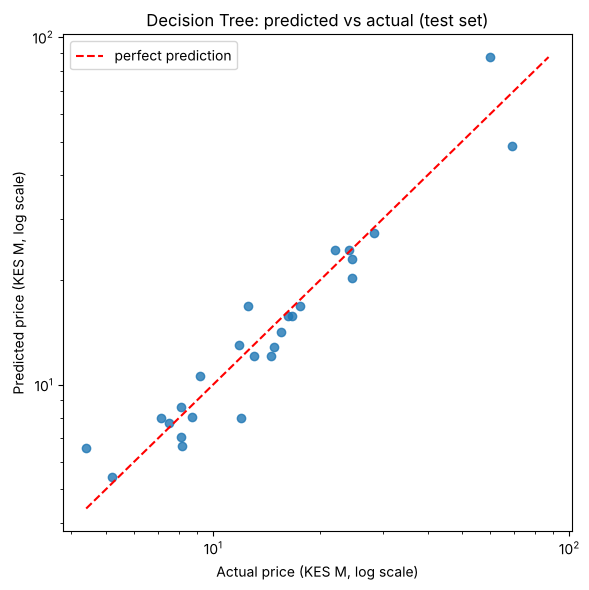

In [46]:
# ---- Final evaluation on the held-out TEST set (used once) ----
dt_test_pred = dt_best_model.predict(X_test)

dt_final_rows = [
    dt_evaluate(y_test, dummy_mean.predict(X_test_processed), 'Mean baseline'),
    dt_evaluate(y_test, dummy_median.predict(X_test_processed), 'Median baseline'),
    dt_evaluate(y_test, dt_test_pred, 'Decision Tree (tuned)'),
]
# Add the group's best linear model for comparison if that cell has been run
if 'lr_best_model' in globals():
    dt_final_rows.insert(2, dt_evaluate(y_test, lr_best_model.predict(X_test),
                                        f'{lr_best_name} (tuned)'))

dt_final = pd.DataFrame(dt_final_rows).set_index('Model')
display(dt_final.round(2))

# 95% bootstrap interval for the test MAE
dt_rng = np.random.default_rng(1089)
dt_abs_err = np.abs(np.asarray(y_test) - dt_test_pred)
dt_boot = [dt_rng.choice(dt_abs_err, size=len(dt_abs_err), replace=True).mean() for _ in range(2000)]
print(f"Test MAE = {dt_abs_err.mean():,.0f} KES, 95% bootstrap interval "
      f"[{np.percentile(dt_boot, 2.5):,.0f}, {np.percentile(dt_boot, 97.5):,.0f}]")

# Predicted vs actual
plt.figure(figsize=(6, 6))
plt.scatter(np.asarray(y_test) / 1e6, dt_test_pred / 1e6, alpha=0.8)
dt_lim = [min(np.min(y_test), dt_test_pred.min()) / 1e6, max(np.max(y_test), dt_test_pred.max()) / 1e6]
plt.plot(dt_lim, dt_lim, 'r--', label='perfect prediction')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Actual price (KES M, log scale)'); plt.ylabel('Predicted price (KES M, log scale)')
plt.title('Decision Tree: predicted vs actual (test set)')
plt.legend(); plt.tight_layout(); plt.show()

### Decision Tree: feature importance and tree structure

,feature,importance
0,num__bedrooms,0.617
3,num__size_sqft,0.147
10,cat__property_type_Apartment,0.118
1,num__bathrooms,0.081
7,cat__location_Syokimau,0.015
2,num__parking,0.009
12,cat__property_type_infrequent_sklearn,0.005
8,cat__location_Westlands,0.004
9,cat__location_infrequent_sklearn,0.004
4,cat__location_Kileleshwa,0.001


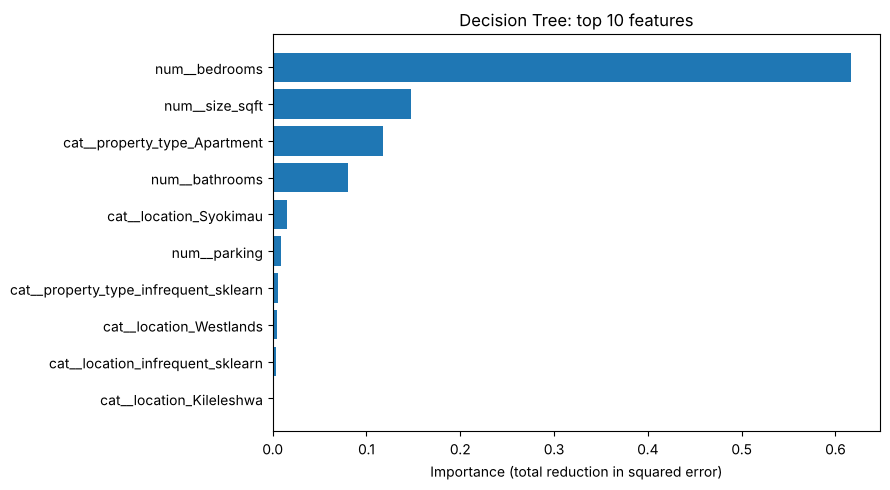

Tree depth: 8, number of leaves: 52


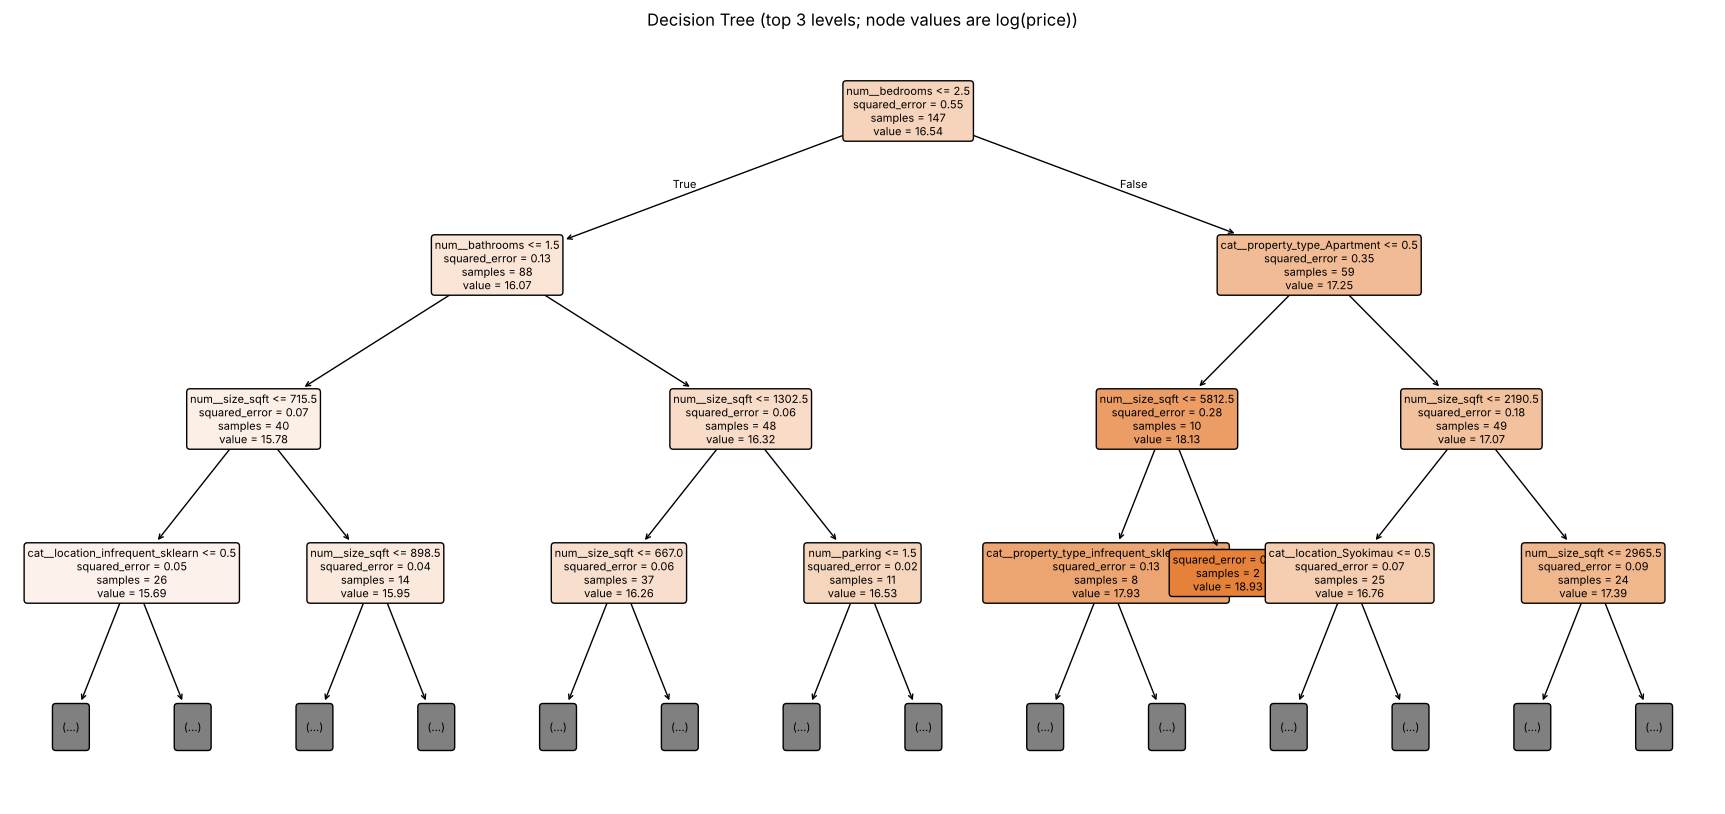

|--- num__bedrooms <= 2.50
|   |--- num__bathrooms <= 1.50
|   |   |--- num__size_sqft <= 715.50
|   |   |   |--- cat__location_infrequent_sklearn <= 0.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- cat__location_infrequent_sklearn >  0.50
|   |   |   |   |--- value: [15.32]
|   |   |--- num__size_sqft >  715.50
|   |   |   |--- num__size_sqft <= 898.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- num__size_sqft >  898.50
|   |   |   |   |--- value: [16.30]
|   |--- num__bathrooms >  1.50
|   |   |--- num__size_sqft <= 1302.50
|   |   |   |--- num__size_sqft <= 667.00
|   |   |   |   |--- value: [16.80]
|   |   |   |--- num__size_sqft >  667.00
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- num__size_sqft >  1302.50
|   |   |   |--- num__parking <= 1.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- num__parking >  1.50
|   |   |   |   |--- value: [16.75]
|--- num__bedrooms >  2.50
|   |--- cat__property_type_

In [47]:
# ---- Interpretation: feature importance and the learned tree ----
dt_prep = dt_best_model.regressor_.named_steps['prep']
dt_tree = dt_best_model.regressor_.named_steps['model']
dt_feature_names = dt_prep.get_feature_names_out()

dt_importance = (pd.DataFrame({'feature': dt_feature_names,
                               'importance': dt_tree.feature_importances_})
                 .sort_values('importance', ascending=False))
display(dt_importance.head(10).round(3))

dt_top = dt_importance.head(10).iloc[::-1]
plt.figure(figsize=(9, 5))
plt.barh(dt_top['feature'], dt_top['importance'])
plt.xlabel('Importance (total reduction in squared error)')
plt.title('Decision Tree: top 10 features')
plt.tight_layout(); plt.show()

print(f"Tree depth: {dt_tree.get_depth()}, number of leaves: {dt_tree.get_n_leaves()}")

# Draw the tree (limited to the top 3 levels so it stays readable)
plt.figure(figsize=(22, 10))
plot_tree(dt_tree, feature_names=dt_feature_names, max_depth=3,
          filled=True, rounded=True, fontsize=8, precision=2)
plt.title('Decision Tree (top 3 levels; node values are log(price))')
plt.show()

# Plain-text rules, also top 3 levels only
print(export_text(dt_tree, feature_names=list(dt_feature_names), max_depth=3))

## Random Forest Regression

A random forest averages many decision trees. Each tree is trained on a random bootstrap sample of the rows and considers only a random subset of the features at every split, so the trees make different mistakes and averaging them removes most of the overfitting that a single deep tree suffers from. Like the tree, it needs no feature scaling. We (1) compare untuned forests on the validation set, (2) tune the main hyperparameters with the same 5-fold cross-validation on train+validation only, and (3) report the held-out test set once, next to the baselines, the linear model and the decision tree.

Run this section after the linear-model and decision-tree cells (it reuses `X_train`, `X_val`, `X_test`, `X_dev`, `y_*`, `cv`, `numerical_features`, `categorical_features`, `dummy_mean`/`dummy_median`, `lr_best_model` and `dt_best_model`).

In [48]:
# ================= RANDOM FOREST REGRESSION =================
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.inspection import permutation_importance
import joblib

# Forests, like trees, split on thresholds, so scaling is unnecessary. We impute, flag the imputed numeric
# values (bathrooms is mostly missing for houses, so "missing" is itself informative) and encode.
rf_preprocessor = ColumnTransformer(transformers=[
    ('num', SimpleImputer(strategy='median', add_indicator=True), numerical_features),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('encoder', OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                min_frequency=5))]), categorical_features),
])

def rf_make_model(log_target=True, **rf_params):
    forest = RandomForestRegressor(random_state=1089, n_jobs=1, **rf_params)
    pipe = Pipeline([('prep', clone(rf_preprocessor)), ('model', forest)])
    if log_target:
        return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)
    return pipe

def rf_evaluate(y_true, y_pred, name):
    y_true = np.asarray(y_true)
    return {
        'Model': name,
        'MAE (KES)': mean_absolute_error(y_true, y_pred),
        'RMSE (KES)': mean_squared_error(y_true, y_pred) ** 0.5,
        'R2': r2_score(y_true, y_pred),
        'MedAPE (%)': np.median(np.abs(y_pred - y_true) / y_true) * 100,
    }

# Untuned forests, fitted on the TRAINING set only and scored on the VALIDATION set
rf_candidates = {
    'Forest (raw price, defaults)':                     rf_make_model(log_target=False, n_estimators=300),
    'Forest (log price, defaults)':                     rf_make_model(n_estimators=300),
    'Forest (log price, max_depth=6, min_leaf=2)':      rf_make_model(n_estimators=300, max_depth=6, min_samples_leaf=2),
}

rf_rows = []
for rf_name, rf_model in rf_candidates.items():
    rf_model.fit(X_train, y_train)
    rf_rows.append(rf_evaluate(y_train, rf_model.predict(X_train), rf_name + ' [train]'))
    rf_rows.append(rf_evaluate(y_val, rf_model.predict(X_val), rf_name + ' [validation]'))

rf_val_results = pd.DataFrame(rf_rows).set_index('Model')
display(rf_val_results.round(2))
print("Forests always fit their own training rows closely, so the train scores are flattering. Compare the validation rows.")

,MAE (KES),RMSE (KES),R2,MedAPE (%)
Model,,,,
"Forest (raw price, defaults) [train]",2189637.54,5515088.46,0.96,5.76
"Forest (raw price, defaults) [validation]",2906290.44,6505501.82,0.80,11.55
"Forest (log price, defaults) [train]",2236102.54,6607178.07,0.94,5.26
"Forest (log price, defaults) [validation]",2601283.11,6546724.46,0.80,10.45
"Forest (log price, max_depth=6, min_leaf=2) [train]",3279162.56,10457414.07,0.85,8.39
"Forest (log price, max_depth=6, min_leaf=2) [validation]",2671002.41,6705649.96,0.79,9.29


Forests always fit their own training rows closely, so the train scores are flattering. Compare the validation rows.


### Random Forest: tuning with cross-validation

In [49]:
# ---- Hyperparameter tuning with 5-fold cross-validation (train + validation only) ----
# RandomizedSearchCV tries 60 random combinations (4,800 possible), because a full grid of forests would be slow.
rf_param_dist = {
    'regressor__model__n_estimators':      [100, 200, 300, 500],
    'regressor__model__max_depth':         [None, 4, 6, 8, 12],
    'regressor__model__min_samples_split': [2, 4, 6, 10],
    'regressor__model__min_samples_leaf':  [1, 2, 3, 5],
    'regressor__model__max_features':      ['sqrt', 0.3, 0.5, 0.7, 1.0],
    'regressor__model__max_samples':       [None, 0.6, 0.8],
}

rf_search = RandomizedSearchCV(
    rf_make_model(),
    rf_param_dist,
    n_iter=60,
    cv=cv,                                   # same KFold(5, shuffle, seed 1089) as the linear and tree models
    scoring='neg_mean_absolute_error',
    random_state=1089,
    n_jobs=-1,
)
rf_search.fit(X_dev, y_dev)                  # the test set is NOT used here

print("Best parameters:")
for rf_k, rf_v in rf_search.best_params_.items():
    print("  ", rf_k.replace('regressor__model__', ''), "=", rf_v)
print(f"Best cross-validated MAE: {-rf_search.best_score_:,.0f} KES")

# Is tuning actually better than the default forest? (same folds, same metric)
rf_default_cv_mae = -cross_val_score(rf_make_model(n_estimators=300), X_dev, y_dev, cv=cv,
                                     scoring='neg_mean_absolute_error').mean()
print(f"Default forest cross-validated MAE: {rf_default_cv_mae:,.0f} KES")

rf_cv_results = (pd.DataFrame(rf_search.cv_results_)
                 .assign(cv_mae=lambda d: -d['mean_test_score'])
                 .sort_values('cv_mae')
                 [['param_regressor__model__n_estimators', 'param_regressor__model__max_depth',
                   'param_regressor__model__min_samples_split', 'param_regressor__model__min_samples_leaf',
                   'param_regressor__model__max_features', 'param_regressor__model__max_samples', 'cv_mae']]
                 .head(10))
rf_cv_results.columns = ['n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf',
                         'max_features', 'max_samples', 'cv_mae']
display(rf_cv_results.round(0))

rf_best_model = rf_search.best_estimator_    # already refitted on all of X_dev

Best parameters:
   n_estimators = 100
   min_samples_split = 2
   min_samples_leaf = 1
   max_samples = 0.8
   max_features = 0.3
   max_depth = 12
Best cross-validated MAE: 5,094,302 KES


Default forest cross-validated MAE: 5,241,265 KES


,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,max_samples,cv_mae
18,100,12,2,1,0.3,0.8,5094302.0
51,300,8,2,2,0.5,None,5299985.0
30,500,6,2,1,sqrt,0.8,5302178.0
24,500,None,2,1,sqrt,0.6,5324472.0
23,100,8,4,2,0.5,0.8,5346076.0
19,200,6,4,2,1.0,0.8,5362301.0
53,200,6,2,2,1.0,0.8,5362301.0
9,100,8,4,1,1.0,0.6,5364601.0
26,200,None,6,1,1.0,0.8,5388108.0
57,300,12,6,2,0.5,None,5404916.0


**Reading the tuning results**
- The best setting (100 trees, `max_depth=12`, `max_features=0.3`, `max_samples=0.8`) has a cross-validated MAE of about KES 5.09M, versus 5.24M for the default forest: a gain of about 3%.
- The top 10 settings all lie between 5.09M and 5.40M, so many settings are about equally good. The winner is a sensible choice, not proof that it is uniquely best.
- As with the other models, this CV score is slightly optimistic because the settings were chosen on the same folds.

### Random Forest: final evaluation on the test set

,MAE (KES),RMSE (KES),R2,MedAPE (%)
Model,,,,
Mean baseline,11839534.33,15560695.76,-0.08,69.22
Median baseline,8912500.00,15526051.71,-0.08,44.73
OLS (log price) (tuned),2681370.56,3954285.35,0.93,11.14
Decision Tree (tuned),3236991.44,6975135.95,0.78,10.30
Random Forest (default),1386377.57,1681989.56,0.99,7.59
Random Forest (tuned),1866624.47,2511444.35,0.97,9.01


Test MAE = 1,866,624 KES, 95% bootstrap interval [1,280,334, 2,550,049]  (n = 26 test listings)


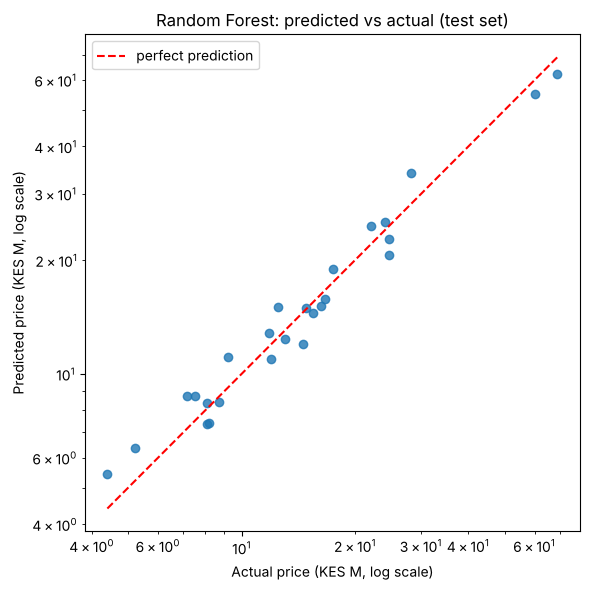

In [50]:
# ---- Final evaluation on the held-out TEST set (used once) ----
rf_default_model = rf_make_model(n_estimators=300).fit(X_dev, y_dev)   # untuned forest, same training rows as the tuned one
rf_test_pred = rf_best_model.predict(X_test)

rf_final_rows = [
    rf_evaluate(y_test, dummy_mean.predict(X_test_processed), 'Mean baseline'),
    rf_evaluate(y_test, dummy_median.predict(X_test_processed), 'Median baseline'),
]
# Add the group's linear model and decision tree for comparison if those cells have been run
if 'lr_best_model' in globals():
    rf_final_rows.append(rf_evaluate(y_test, lr_best_model.predict(X_test), f'{lr_best_name} (tuned)'))
if 'dt_best_model' in globals():
    rf_final_rows.append(rf_evaluate(y_test, dt_best_model.predict(X_test), 'Decision Tree (tuned)'))
rf_final_rows.append(rf_evaluate(y_test, rf_default_model.predict(X_test), 'Random Forest (default)'))
rf_final_rows.append(rf_evaluate(y_test, rf_test_pred, 'Random Forest (tuned)'))

rf_final = pd.DataFrame(rf_final_rows).set_index('Model')
display(rf_final.round(2))

# 95% bootstrap interval for the test MAE
rf_rng = np.random.default_rng(1089)
rf_abs_err = np.abs(np.asarray(y_test) - rf_test_pred)
rf_boot = [rf_rng.choice(rf_abs_err, size=len(rf_abs_err), replace=True).mean() for _ in range(2000)]
print(f"Test MAE = {rf_abs_err.mean():,.0f} KES, 95% bootstrap interval "
      f"[{np.percentile(rf_boot, 2.5):,.0f}, {np.percentile(rf_boot, 97.5):,.0f}]  (n = {len(y_test)} test listings)")

# Predicted vs actual
plt.figure(figsize=(6, 6))
plt.scatter(np.asarray(y_test) / 1e6, rf_test_pred / 1e6, alpha=0.8)
rf_lim = [min(np.min(y_test), rf_test_pred.min()) / 1e6, max(np.max(y_test), rf_test_pred.max()) / 1e6]
plt.plot(rf_lim, rf_lim, 'r--', label='perfect prediction')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Actual price (KES M, log scale)'); plt.ylabel('Predicted price (KES M, log scale)')
plt.title('Random Forest: predicted vs actual (test set)')
plt.legend(); plt.tight_layout(); plt.show()

**Reading the test results**
- Both forests have the lowest error on the test set: MAE KES 1.39M (default) and 1.87M (tuned), versus 2.68M for the linear model and 3.24M for the decision tree. They also have the lowest typical percentage error (MedAPE 7.6% and 9.0%, versus 11.1% and 10.3%).
- **The tuned forest did not beat the default one here**, even though it was better in cross-validation. With only 26 test listings that difference is noise, and the 95% interval for the tuned MAE is wide (about 1.28M to 2.55M).
- **This test set is an easy one:** it holds 24 apartments, 1 house and 1 townhouse, and its highest price is KES 69M. The most expensive listings (220M, 125M, 85M and others) are all in the development set. Scores on it therefore flatter every model, so the test table should be read together with the cross-validation column in the comparison at the end.

### Random Forest: where does it make errors?

In [51]:
# Out-of-fold errors on all development rows (more stable than the small test set), as for the linear model
rf_oof = cross_val_predict(clone(rf_best_model), X_dev, y_dev, cv=cv)
rf_oof_df = X_dev.copy()
rf_oof_df['actual'] = y_dev.values
rf_oof_df['predicted'] = rf_oof
rf_oof_df['abs_pct_error'] = np.abs(rf_oof - rf_oof_df['actual']) / rf_oof_df['actual'] * 100
rf_oof_df['price_band'] = pd.qcut(rf_oof_df['actual'], 3, labels=['low', 'mid', 'high'])
rf_oof_df['direction'] = np.where(rf_oof_df['predicted'] > rf_oof_df['actual'], 'over', 'under')

for rf_col in ['property_type', 'price_band']:
    display(rf_oof_df.groupby(rf_col, observed=True)['abs_pct_error'].agg(['count', 'median']).round(1))
display(pd.crosstab(rf_oof_df['price_band'], rf_oof_df['direction'], normalize='index').round(2))

rf_test_res = X_test.copy()
rf_test_res['actual'] = y_test.values
rf_test_res['predicted'] = rf_test_pred
rf_test_res['abs_pct_error'] = np.abs(rf_test_res['predicted'] - rf_test_res['actual']) / rf_test_res['actual'] * 100
print("Five largest test errors")
display(rf_test_res.sort_values('abs_pct_error', ascending=False).head(5)
        [['location', 'property_type', 'bedrooms', 'size_sqft', 'actual', 'predicted', 'abs_pct_error']].round(1))

,count,median
property_type,,
Apartment,137,12.2
House,4,34.1
Townhouse,6,47.0


,count,median
price_band,,
low,49,16.9
mid,49,5.9
high,49,16.8


direction,over,under
price_band,,
low,0.65,0.35
mid,0.43,0.57
high,0.41,0.59


Five largest test errors


,location,property_type,bedrooms,size_sqft,actual,predicted,abs_pct_error
12,Syokimau,Apartment,1.0,603.0,4400000,5442735.3,23.7
34,Kilimani,Apartment,NaN,463.0,5200000,6362437.0,22.4
156,Kileleshwa,Apartment,2.0,861.0,7150000,8727377.3,22.1
86,Kilimani,Apartment,5.0,2799.0,28200000,34056804.8,20.8
49,Kileleshwa,Apartment,2.0,1087.0,9210000,11086527.0,20.4


- **Apartments** (137 of 147 development rows): the forest's typical error is about 12%, slightly better than the linear model's 14% in the earlier cell.
- **Houses and townhouses** (only 10 rows): typical errors of 34% and 47%. The forest is not better than the linear model here (25% for townhouses). A forest cannot predict above the prices it has seen, and there are very few examples.
- It tends to **over-predict cheap homes and under-predict expensive ones** (65% over for the low price band, 59% under for the high band), the usual averaging effect.
- The five largest test errors are all apartments at about 20% to 24%, so no single test listing is badly wrong.

### Random Forest: feature importance

,feature,importance
3,num__size_sqft,0.283
0,num__bedrooms,0.283
1,num__bathrooms,0.137
2,num__parking,0.131
14,cat__property_type_Apartment,0.052
15,cat__property_type_Townhouse,0.041
13,cat__location_infrequent_sklearn,0.019
5,num__missingindicator_bathrooms,0.013
12,cat__location_Westlands,0.010
11,cat__location_Syokimau,0.009


,feature,mae_increase_KES,std
2,bedrooms,2622622.0,632805.0
5,size_sqft,2195020.0,549454.0
1,property_type,1436782.0,292253.0
3,bathrooms,1294391.0,462041.0
4,parking,895892.0,348039.0
0,location,858858.0,226233.0


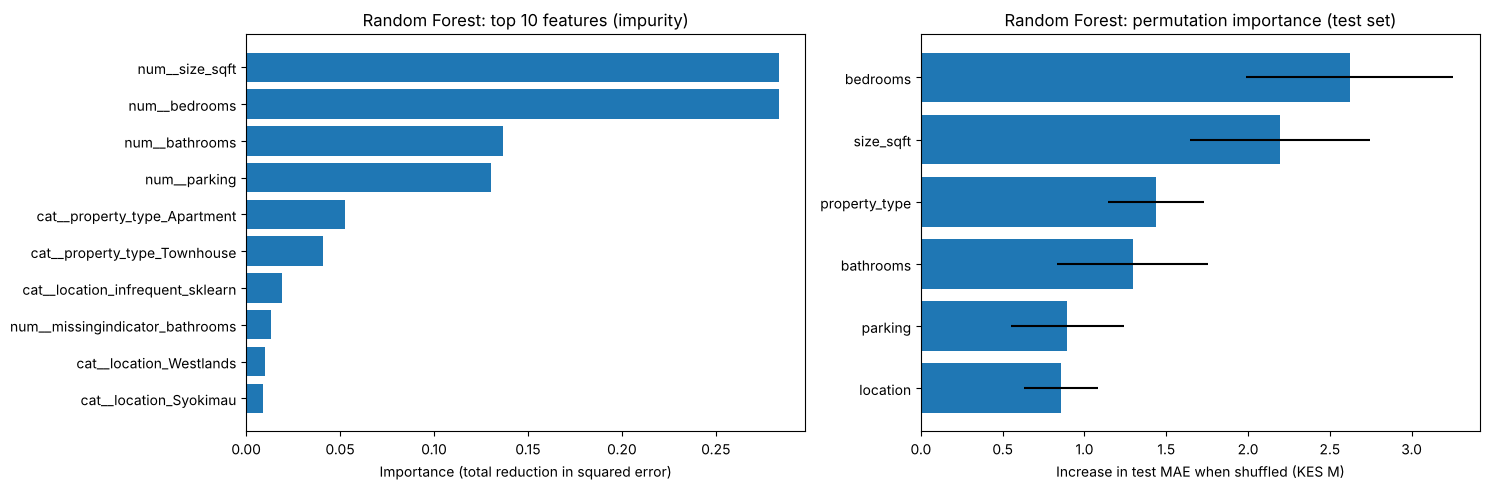

Number of trees: 100, average leaves per tree: 74


In [52]:
# ---- Interpretation: impurity importance and permutation importance ----
rf_prep = rf_best_model.regressor_.named_steps['prep']
rf_forest = rf_best_model.regressor_.named_steps['model']
rf_feature_names = rf_prep.get_feature_names_out()

rf_importance = (pd.DataFrame({'feature': rf_feature_names, 'importance': rf_forest.feature_importances_})
                 .sort_values('importance', ascending=False))
display(rf_importance.head(10).round(3))

# Permutation importance on the ORIGINAL columns (shuffle one column, see how much the error grows).
# More reliable than impurity importance here because bedrooms, bathrooms and size are strongly correlated.
# It is computed on the test set for interpretation only; no modelling choice was made with it.
rf_perm = permutation_importance(rf_best_model, X_test, y_test, scoring='neg_mean_absolute_error',
                                 n_repeats=30, random_state=1089, n_jobs=1)
rf_perm_df = (pd.DataFrame({'feature': X_test.columns, 'mae_increase_KES': rf_perm.importances_mean,
                            'std': rf_perm.importances_std})
              .sort_values('mae_increase_KES', ascending=False))
display(rf_perm_df.round(0))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
rf_top = rf_importance.head(10).iloc[::-1]
ax[0].barh(rf_top['feature'], rf_top['importance'])
ax[0].set_xlabel('Importance (total reduction in squared error)'); ax[0].set_title('Random Forest: top 10 features (impurity)')
rf_pm = rf_perm_df.iloc[::-1]
ax[1].barh(rf_pm['feature'], rf_pm['mae_increase_KES'] / 1e6, xerr=rf_pm['std'] / 1e6)
ax[1].set_xlabel('Increase in test MAE when shuffled (KES M)'); ax[1].set_title('Random Forest: permutation importance (test set)')
plt.tight_layout(); plt.show()
print(f"Number of trees: {rf_forest.n_estimators}, average leaves per tree: {np.mean([t.get_n_leaves() for t in rf_forest.estimators_]):.0f}")

- **Bedrooms** and **size** are the strongest drivers (permutation importance: shuffling them raises the test MAE by about KES 2.6M and 2.2M), followed by property type, bathrooms and parking. Location ranks lowest, partly because three areas make up most of the data and its signal overlaps with property type and size.
- Bedrooms, bathrooms and size are strongly correlated, so their individual ranking should not be over-read. Impurity importance tends to favour numeric features, which is why parking looks larger there; rely on the permutation ranking. Both describe what the model uses, not what causes prices.

### Random Forest: save the final model

In [53]:
# rf_best_model was refitted on all development rows (train + validation) by the search.
joblib.dump({'model': rf_best_model,
             'features': list(X.columns),
             'note': 'predicts price_kes directly (log transform is built into the model)'},
            'rf_property_price_model.joblib')

rf_example = pd.DataFrame([{'location': 'Kilimani', 'property_type': 'Apartment', 'bedrooms': 2,
                            'bathrooms': 2, 'parking': 1, 'size_sqft': 1100}])
print(f"Example: 2-bedroom Kilimani apartment, 1,100 sqft -> KES {rf_best_model.predict(rf_example[list(X.columns)])[0]:,.0f}")

Example: 2-bedroom Kilimani apartment, 1,100 sqft -> KES 10,537,144


## Model comparison

In [54]:
# All models side by side: cross-validated MAE (train + validation) and the single test-set evaluation
rf_compare = pd.DataFrame({
    'CV MAE (KES)': {
        f'{lr_best_name} (tuned)': lr_cv_mae[lr_best_name],
        'Decision Tree (tuned)': -dt_gs.best_score_,
        'Random Forest (default)': rf_default_cv_mae,
        'Random Forest (tuned)': -rf_search.best_score_,
    }
})
rf_compare = rf_compare.join(rf_final[['MAE (KES)', 'RMSE (KES)', 'R2', 'MedAPE (%)']].add_prefix('Test '))
display(rf_compare.round(2))

,CV MAE (KES),Test MAE (KES),Test RMSE (KES),Test R2,Test MedAPE (%)
OLS (log price) (tuned),4959723.59,2681370.56,3954285.35,0.93,11.14
Decision Tree (tuned),4884624.35,3236991.44,6975135.95,0.78,10.30
Random Forest (default),5241264.52,1386377.57,1681989.56,0.99,7.59
Random Forest (tuned),5094301.90,1866624.47,2511444.35,0.97,9.01


**Summary**
- **In cross-validation on all 147 development rows, the three model families are close** (MAE KES 4.9M to 5.2M). The tuned forest is not better than the linear model or the tree on this measure, because MAE in KES is dominated by a handful of very expensive houses that none of the models can predict well.
- **On the test set the forests are clearly best**, but that set is small (26) and contains no listing above KES 69M, so it flatters all models.
- **Tuning** gave a small cross-validation gain for the forest (about 3%) that did not carry over to the test set.
- **Practical reading:** the Random Forest is a good choice for typical apartments (about 9% to 12% typical error), while the rare, very expensive houses and townhouses remain the weak spot for every model. More examples of those, not more tuning, would help most.